# 🔹 Figure 3A

## (1) Prepare data

In [ ]:
import pandas as pd

pcts = [0.02, 0.05, 0.1, 0.3, 0.5, 0.7, 0.8]
SEEDS = list(range(42, 53))
root_path = "./result/section_2/GPN_CaLM_NewBio/"
results = pd.read_csv(f"{root_path}/metrics.txt", sep='\t')

## (2) Plot box & Statistic

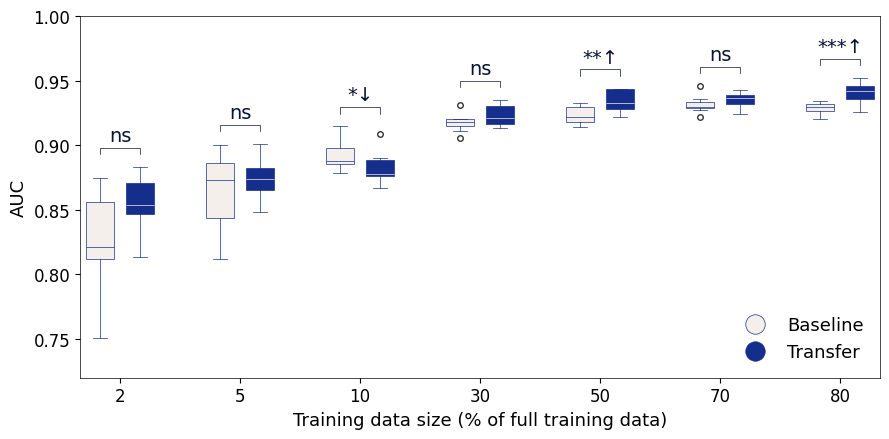

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_rel

metrics = "AUC" # AUC | AUPR
fig, ax = plt.subplots(figsize=(9, 4.5))

inner_colors = ["#f4efeb", '#152e8b']
edge_colors = ["#152e8b", "#152e8b"]
median_colors = ["#152e8b", "#f4efeb"]
linewidth = 0.5

positions = []
labels = []
data_to_plot = []

# Organize data
for i, pct in enumerate(pcts):
    for j, strat in enumerate([False, True]):
        subset = results[
            (results["pct"] == pct) &
            (results["TRANSFER"] == strat)
        ]
        data_to_plot.append(subset[metrics].values)
        positions.append(i*3 + j + 1)

        if j == 0:
            labels.append(str(int(pct * 100)))

# Plot boxplot
bp = ax.boxplot(
    data_to_plot,
    widths=0.7,
    positions=positions,
    patch_artist=True
)

# Box styling
for idx, box in enumerate(bp['boxes']):
    group_idx = idx % 2
    box.set_facecolor(inner_colors[group_idx])
    box.set_edgecolor(edge_colors[group_idx])
    box.set_linewidth(linewidth)

for idx, median in enumerate(bp['medians']):
    group_idx = idx % 2
    median.set_color(median_colors[group_idx])
    median.set_linewidth(linewidth)

for idx, whisker in enumerate(bp['whiskers']):
    group_idx = idx // 2 % 2
    whisker.set_color(edge_colors[group_idx])
    whisker.set_linewidth(linewidth)

for idx, cap in enumerate(bp['caps']):
    group_idx = idx // 2 % 2
    cap.set_color(edge_colors[group_idx])
    cap.set_linewidth(linewidth)

for idx, flier in enumerate(bp['fliers']):
    group_idx = idx % 2
    flier.set_marker('o')
    flier.set_markersize(4)
    flier.set_markeredgecolor('#333')

# Add significance markers
def significance_marker(p, arrow):
    if p < 0.001:
        return "***" + arrow
    elif p < 0.01:
        return "**" + arrow
    elif p < 0.05:
        return "*" + arrow
    else:
        return "ns"

y_max = ax.get_ylim()[1]
for i, pct in enumerate(pcts):
    baseline = results[
        (results["pct"] == pct) &
        (results["TRANSFER"] == False)
    ][metrics].values

    transfer = results[
        (results["pct"] == pct) &
        (results["TRANSFER"] == True)
    ][metrics].values
    
    # Calculate direction of effect
    diff = transfer.mean() - baseline.mean()
    arrow = '↑' if diff > 0 else '↓'

    # Calculate statistical significance
    stat, p = ttest_rel(baseline, transfer, nan_policy='omit')
    mark = significance_marker(p, arrow)

    # Positions of the two boxes
    x1 = i*3 + 1
    x2 = i*3 + 2
    x_center = (x1 + x2) / 2

    # Highest point of current group
    y = max(np.max(baseline), np.max(transfer)) + 0.01

    # Draw horizontal line
    ax.plot([x1, x1, x2, x2],
            [y, y+0.005, y+0.005, y],
            linewidth=linewidth,
            color='#081236')

    # Add asterisk
    ax.text(x_center, y+0.007,
            mark,
            ha='center',
            va='bottom',
            fontsize=14,
            fontweight='100',
            color="#081236"
            )

# legend
from matplotlib.lines import Line2D
markersize = 14
markercolor = '#152e8b'
baseline_patch = Line2D(
    [0], [0],
    marker='o',
    linestyle='None',
    markersize=markersize,
    markerfacecolor=inner_colors[0],
    markeredgecolor=markercolor,
    markeredgewidth=0.5,
    label="Baseline"
)

transfer_patch = Line2D(
    [0], [0],
    marker='o',
    linestyle='None',
    markersize=markersize,
    markerfacecolor=inner_colors[1],
    markeredgecolor=markercolor,
    markeredgewidth=0.5,
    label="Transfer"
)

ax.legend(
    handles=[baseline_patch, transfer_patch],
    fontsize=13,
    frameon=False,
    loc='lower right'
)

# Axes
ax.set_xticks([i*3 + 1.5 for i in range(len(pcts))], labels)
ax.set_xlabel("Training data size (% of full training data)", fontsize=13)
ax.set_ylabel(metrics, fontsize=13)
ax.tick_params(axis='both', labelsize=12)
ax.set_ylim(0.72, 1)
# ax.set_ylim(0.7, 1)

# Set border thickness
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.tight_layout()
plt.show()

# 🔹 Figure 3B

## (1) Load pkgs

In [ ]:
import os
import torch
from torch.utils.data import ConcatDataset, DataLoader

import yaml
import warnings
warnings.filterwarnings("ignore")

import umap
import numpy as np
import matplotlib.pyplot as plt

os.environ["CUDA_VISIBLE_DEVICES"] = "1"  # "1"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[Debug] Using device: {device}")
print(f"[Debug] CUDA_VISIBLE_DEVICES = {os.environ['CUDA_VISIBLE_DEVICES']}")
print(f"[Debug] torch.cuda.current_device() = {torch.cuda.current_device()}")
print(f"[Debug] torch.cuda.get_device_name(0) = {torch.cuda.get_device_name(0)}")

from functions.Dataset import MyDataset, concat_and_loader
from functions.Utils import set_full_deterministic_seed

from functions.TranSynAttention import TranSynAttention
from functions.ModelScaffold import build_backbone
from functions.DyPositionTransformer import DyPositionTransformer
model_combo = "GPN_CaLM_NewBio"

with open('./config/config.yaml', 'r', encoding='utf-8') as file:
	config = yaml.safe_load(file)
	base_config = config['base']
	spc_config = config[model_combo]

[Debug] Using device: cuda
[Debug] CUDA_VISIBLE_DEVICES = 1
[Debug] torch.cuda.current_device() = 0
[Debug] torch.cuda.get_device_name(0) = NVIDIA GeForce RTX 3090


## (2) Build model

In [4]:
tsa_dna_module = build_backbone(name="ResNet1D", seq_len=129, embed_dim=768)
tsa_rna_module = DyPositionTransformer(
									input_dim=768,
									num_layers=4,
									d_model=256,
									num_heads=4,
									dff=512,
									dropout_rate=0.1,
									head_hidden=128,
							).to(device) 
tsa_bio_module = build_backbone(name="MLP", embed_dim=49, output_dim=spc_config['BIO_HIDDEN']).to(device) 
my_model = TranSynAttention(
			dna_module = tsa_dna_module,
			rna_module = tsa_rna_module,
			bio_module = tsa_bio_module,
			hidden_layer = spc_config['HEAD_HIDDEN'],
			dropout = spc_config['DROPOUT_RATE'],
		).to(device) 

## (3) Load training data

In [ ]:
TARGET_ROOT_PATH = "./feature/"
train_data_bn = MyDataset(data_path=f"{TARGET_ROOT_PATH}/train_target_neg.pth", label=0)
train_data_pt = MyDataset(data_path=f"{TARGET_ROOT_PATH}/train_target_pos.pth", label=1)
train_data = ConcatDataset([train_data_bn, train_data_pt])
test_data_bn = MyDataset(data_path=f"{TARGET_ROOT_PATH}/test_target_neg.pth", label=0)
test_data_pt = MyDataset(data_path=f"{TARGET_ROOT_PATH}/test_target_pos.pth", label=1)
test_data = ConcatDataset([test_data_bn, test_data_pt])

## (4) Plot UMAP

Transfer=True | DNA | Train


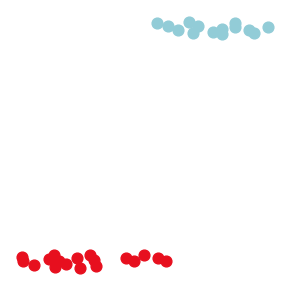

Transfer=True | RNA | Train


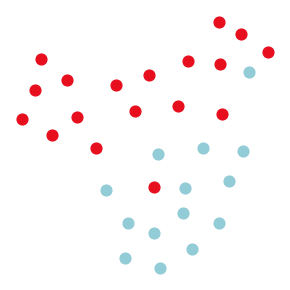

Transfer=True | DNA | Test


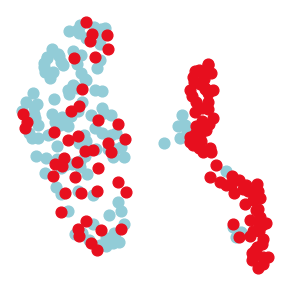

Transfer=True | RNA | Test


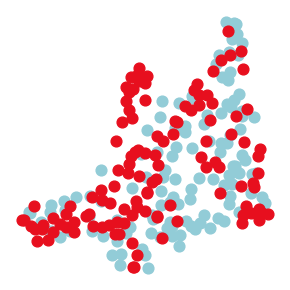

Transfer=False | DNA | Train


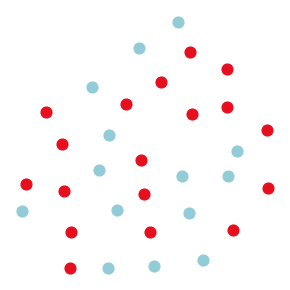

Transfer=False | RNA | Train


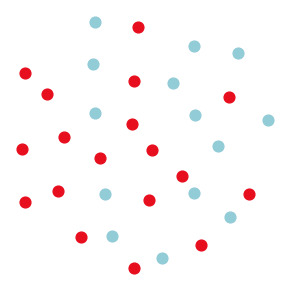

Transfer=False | DNA | Test


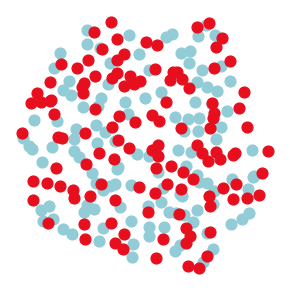

Transfer=False | RNA | Test


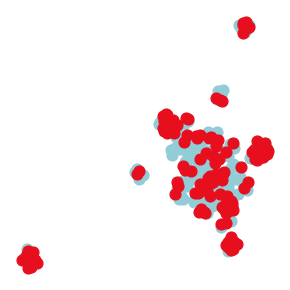

In [ ]:
# config
COLOR_MAP = {
	0: "#92ccd7",
	1: "#e70f1e"
}
SEED = 44 # the SEED of final model

# feature extractor
@torch.no_grad()
def extract_features(model, loader, device):
	model.eval()

	dna_list, rna_list, label_list = [], [], []
	for batch in loader:
		dna_x = batch["gpn_msa"].to(device)
		rna_x = batch["calm_diff"].to(device)
		labels = batch["label"].cpu().numpy()

		dna_feat = model.dna_module(dna_x, use_tsrs=False)
		rna_feat = model.rna_module(rna_x, backbone=True)

		dna_feat = model.norm_dna(model.proj_dna(dna_feat))
		rna_feat = model.norm_rna(model.proj_rna(rna_feat))

		dna_list.append(dna_feat.detach().cpu().numpy())
		rna_list.append(rna_feat.detach().cpu().numpy())
		label_list.append(labels)

	return (
		np.concatenate(dna_list, axis=0),
		np.concatenate(rna_list, axis=0),
		np.concatenate(label_list, axis=0),
	)

# UMAP + plot
def plot_umap(feat, labels, title):
	reducer = umap.UMAP(
		n_neighbors=50,
		min_dist=0.5,
		metric="cosine",
		random_state=42
	)
	emb = reducer.fit_transform(feat)

	plt.figure(figsize=(3, 3))

	for c in [0, 1]:
		idx = labels == c
		plt.scatter(
			emb[idx, 0],
			emb[idx, 1],
			s=60,
			c=COLOR_MAP[c],
			label=str(c)
		)

	# remove border
	ax = plt.gca()
	ax.set_xticks([])
	ax.set_yticks([])
	ax.set_facecolor('none')
	for spine in ax.spines.values():
		spine.set_visible(False)

	print(title)
	plt.tight_layout()
	plt.show()


# main pipeline
pct=0.02
transfer_group = [True, False]
for group in transfer_group:
	set_full_deterministic_seed(SEED)
	model_path = f"./result/section_3/GPN_CaLM_NewBio/0.02_{group}_best.model"
	my_model.load_state_dict(torch.load(model_path, map_location="cpu"))
	my_model = my_model.to(device)
	# loaders
	train_loader, val_loader = concat_and_loader(
		train_data,
		split_rate=pct,
		batch_size=spc_config['BATCH_SIZE'],
		seed=SEED
	)
	test_loader = DataLoader(
		test_data,
		batch_size=32,
		shuffle=False,
		num_workers=4
	)
	train_dna, train_rna, train_y = extract_features(my_model, train_loader, device)
	test_dna, test_rna, test_y = extract_features(my_model, test_loader, device)
	# 8 plots
	# (1) train DNA
	plot_umap(train_dna, train_y, f"Transfer={group} | DNA | Train")
	# (2) train RNA
	plot_umap(train_rna, train_y, f"Transfer={group} | RNA | Train")
	# (3) test DNA
	plot_umap(test_dna, test_y, f"Transfer={group} | DNA | Test")
	# (4) test RNA
	plot_umap(test_rna, test_y, f"Transfer={group} | RNA | Test")

# 🔹 Figure 3D

## (1) Load data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT_PATH = "./result/section_3/layer_wise/metrics.txt"
df = pd.read_csv(ROOT_PATH, sep='\t')
df.head()

## (2) Plot line graph

In [ ]:
layers = sorted(df['Layer'].unique())
seeds = df['SEED'].unique()

plt.figure(figsize=(6, 4.5))

# Define colors and markers for each task type
metric = 'AUPR' # AUC | AUPR
task_colors = {'source': '#6055a4', 'target': '#92c53c'}
task_markers = {'source': 's', 'target': '^'}

for task in ['source', 'target']:
    task_data = df[df['TRANSFER'] == task]
    color = task_colors[task]
    marker = task_markers[task]
    
    # plot scatter
    for seed in seeds:
        seed_data = task_data[task_data['SEED'] == seed]
        if not seed_data.empty:
            plt.scatter(
                seed_data['Layer'], 
                seed_data[metric],
                color=color,
                marker=marker,
                alpha=0.8,
                s=60  
            )

# plot mean and std
for task in ['source', 'target']:
    task_data = df[df['TRANSFER'] == task]
    means = task_data.groupby('Layer')[metric].mean()
    stds = task_data.groupby('Layer')[metric].std()
    color = task_colors[task]
    label = f'{task} (mean±std)'
    # mean line
    plt.plot(layers, means, color=color, linestyle='-.', linewidth=1, alpha=0.5, label=label)
    # std area
    plt.fill_between(
        layers, 
        means - stds, 
        means + stds, 
        color=color, 
        alpha=0.15
    )

# x y label | ticks
plt.xlabel(r'Layer $n$ at which network is pretrained', fontsize=14)
plt.ylabel(metric, fontsize=14)
plt.xticks(layers)
plt.tick_params(axis='both', labelsize=12)

# Set border properties
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(0.5)
    spine.set_color('#333')

# Set legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='s', color='w', markerfacecolor='#6055a4', 
           markersize=10, alpha=0.8, linestyle='None', label='Source'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='#92c53c', 
           markersize=14, alpha=0.8, linestyle='None', label='Target')
]
plt.legend(handles=legend_elements, loc='lower right', fontsize=13, 
           ncols=1, frameon=False)

plt.tight_layout()
plt.show()

# 🔹 Figure 3F

## (1) Prepare data

In [ ]:
import pandas as pd

# Experimental group
ROOT_PATH = "./result/section_3/spatial/"
distance_list = list(range(500, 2500, 500))
auc_list = []
for dis in distance_list:
    auc = pd.read_csv(f"{ROOT_PATH}/noncoding/{dis}/source_ResNet1D_metric.txt", sep='\t').iloc[0]['AUC']
    auc_list.append(auc)
result_df = pd.DataFrame({'Distance': distance_list, 'AUC': auc_list})
amount_df = pd.read_csv("./dataset/spatial_data/noncoding_spatial_dataset/source_amount.info", sep='\t')
result_df = result_df.merge(amount_df, how='left', left_on='Distance', right_on='Distance', suffixes=('', '_m'))

# Control group
SEEDS = [1918, 1917, 74, 310, 913]
records = []
for dis in distance_list:
    for SEED in SEEDS:
        auc = pd.read_csv(
            f"{ROOT_PATH}/noncoding_control/{dis}/SEED_{SEED}/source_ResNet1D_metric.txt",
            sep='\t'
        ).iloc[0]['AUC']
        records.append({
            "Distance": dis,
            "Seed": SEED,
            "AUC": auc
        })
result_df_2 = pd.DataFrame(records)
# Calculate mean and std
control_stat_df = (
    result_df_2
    .groupby("Distance")["AUC"]
    .agg(["mean", "std"])
    .reset_index()
)

## (2) Plot Bar

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
import numpy as np

LIMIT_DISTANCE = 2000  # Set to None to disable filtering

# 1. Data filtering
if LIMIT_DISTANCE is not None:
    plot_df = result_df[result_df["Distance"] <= LIMIT_DISTANCE].copy()
else:
    plot_df = result_df.copy()
plot_df = plot_df.sort_values("Distance")

# 2. Plotting
fig, ax1 = plt.subplots(figsize=(5, 4.5))
color1 = '#92ccd7' #d15a30 #97b9de
color2 = "#e7e3e0" #4cbddf #b3a0d7
color3 = '#a6a6a6'

x = plot_df["Distance"].values

# AUC line plot
line1, = ax1.plot(
    x,
    plot_df["AUC"],
    marker='o',
    markersize=9,
    markerfacecolor=to_rgba(color1, alpha=1),
    markeredgecolor=color1,
    linewidth=1,
    color=color1,
    label='AUC'
)

# Control group AUC
line2 = ax1.errorbar(
    control_stat_df["Distance"],
    control_stat_df["mean"],
    yerr=control_stat_df["std"],
    marker='s',
    markersize=8,
    markerfacecolor=to_rgba(color2, alpha=1),
    markeredgecolor='#b1aba6',
    linewidth=1,
    color="#b1aba6",
    capsize=3,
    label='Control AUC (mean ± std)'
)

# Add baseline
baseline_y = 0.8316
baseline = ax1.axhline(
    y=baseline_y, 
    color='#e70f1e', 
    linestyle='--', 
    linewidth=1, 
    alpha=0.7,
    label=f'Full source (y={baseline_y})'
)

ax1.set_xlabel("Distance from the target source (bp)", fontsize=12)
ax1.set_ylabel("AUC", fontsize=12)
ax1.tick_params(axis='both', labelsize=11)
ax1.set_xticks(x)
ax1.set_ylim(0.7, 0.9)
from matplotlib.ticker import FuncFormatter

ax1.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:.2f}")
)

ax2 = ax1.twinx()

bar_width = 200

bars = ax2.bar(
    x,
    plot_df["Source_sample_amount"],
    width=bar_width,
    alpha=0.5,
    edgecolor='#000',
    color='None',
    label='Source sample amount'
)

ax2.set_ylabel("Source domain amount", fontsize=12)
ax2.tick_params(axis='y', labelsize=11)

# Combine legends
lines = [bars, line1, line2, baseline]
labels = [
    'Source sample amount',
    'Proximal samples',
    'Distal samples',
    'Full source'
]

ax1.legend(
    lines, 
    labels, 
    frameon=False, 
    # bbox_to_anchor=[0, 1.03],
    fontsize=11, 
    loc='upper left')

# Set z-axis order to make line plots on top
ax1.set_zorder(2)
ax2.set_zorder(1)
ax1.patch.set_visible(False)


# Border styling
for spine in ax1.spines.values():
    spine.set_linewidth(.5)
    spine.set_color('#333')
for spine in ax2.spines.values():
    spine.set_linewidth(.5)
    spine.set_color('#333')


plt.tight_layout()
plt.show()

# 🔹 Figure 3G

## (1) Load data

In [ ]:
import pandas as pd

# Experimental group
ROOT_PATH = "./result/section_3/spatial/"
distance_list = list(range(500, 2500, 500))
auc_list = []
for dis in distance_list:
    auc = pd.read_csv(f"{ROOT_PATH}/missense/{dis}/source_ResNet1D_metric.txt", sep='\t').iloc[0]['AUC']
    auc_list.append(auc)
result_df = pd.DataFrame({'Distance': distance_list, 'AUC': auc_list})
amount_df = pd.read_csv("./dataset/spatial_data/missense_spatial_dataset/source_amount.info", sep='\t')
result_df = result_df.merge(amount_df, how='left', left_on='Distance', right_on='Distance', suffixes=('', '_m'))

# Control group
SEEDS = [1918, 1917, 74, 310, 913]
records = []
for dis in distance_list:
    for SEED in SEEDS:
        auc = pd.read_csv(
            f"{ROOT_PATH}/missense_control/{dis}/SEED_{SEED}/source_ResNet1D_metric.txt",
            sep='\t'
        ).iloc[0]['AUC']
        records.append({
            "Distance": dis,
            "Seed": SEED,
            "AUC": auc
        })
result_df_2 = pd.DataFrame(records)
# Calculate mean and std
control_stat_df = (
    result_df_2
    .groupby("Distance")["AUC"]
    .agg(["mean", "std"])
    .reset_index()
)

## (2) Plot Bar

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
import numpy as np

LIMIT_DISTANCE = 2000  # Set to None to disable filtering

# 1. Data filtering
if LIMIT_DISTANCE is not None:
    plot_df = result_df[result_df["Distance"] <= LIMIT_DISTANCE].copy()
else:
    plot_df = result_df.copy()
plot_df = plot_df.sort_values("Distance")

# 2. Plotting
fig, ax1 = plt.subplots(figsize=(5, 4.5))
color1 = '#92ccd7' #d15a30 #97b9de
color2 = "#e7e3e0" #4cbddf #b3a0d7
color3 = '#a6a6a6'

x = plot_df["Distance"].values

# AUC line plot
line1, = ax1.plot(
    x,
    plot_df["AUC"],
    marker='o',
    markersize=9,
    markerfacecolor=to_rgba(color1, alpha=1),
    markeredgecolor=color1,
    linewidth=1,
    color=color1,
    label='AUC'
)

# Control group AUC
line2 = ax1.errorbar(
    control_stat_df["Distance"],
    control_stat_df["mean"],
    yerr=control_stat_df["std"],
    marker='s',
    markersize=8,
    markerfacecolor=to_rgba(color2, alpha=1),
    markeredgecolor='#b1aba6',
    linewidth=1,
    color="#b1aba6",
    capsize=3,
    label='Control AUC (mean ± std)'
)

# Add baseline
baseline_y = 0.5510
baseline = ax1.axhline(
    y=baseline_y, 
    color='#e70f1e', 
    linestyle='--', 
    linewidth=1, 
    alpha=0.7,
    label=f'Full source (y={baseline_y})'
)

ax1.set_xlabel("Distance from the target source (bp)", fontsize=12)
ax1.set_ylabel("AUC", fontsize=12)
ax1.tick_params(axis='both', labelsize=11)
ax1.set_xticks(x)
ax1.set_ylim(0.7, 0.9)
from matplotlib.ticker import FuncFormatter

ax1.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:.2f}")
)

ax2 = ax1.twinx()

bar_width = 200

bars = ax2.bar(
    x,
    plot_df["Source_sample_amount"],
    width=bar_width,
    alpha=0.5,
    edgecolor='#000',
    color='None',
    label='Source sample amount'
)

ax2.set_ylabel("Source domain amount", fontsize=12)
ax2.tick_params(axis='y', labelsize=11)

# Combine legends
lines = [bars, line1, line2, baseline]
labels = [
    'Source sample amount',
    'Proximal samples',
    'Distal samples',
    'Full source'
]

ax1.legend(
    lines, 
    labels, 
    frameon=False, 
    # bbox_to_anchor=[0, 1.03],
    fontsize=11, 
    loc='upper left')

# Set z-axis order to make line plots on top
ax1.set_zorder(2)
ax2.set_zorder(1)
ax1.patch.set_visible(False)


# Border styling
for spine in ax1.spines.values():
    spine.set_linewidth(.5)
    spine.set_color('#333')
for spine in ax2.spines.values():
    spine.set_linewidth(.5)
    spine.set_color('#333')


plt.tight_layout()
plt.show()